In [9]:
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import os

In [2]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [3]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [5]:
def calc_hist(vals, bins=10, weights=None, density=True):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [6]:
plt.rcParams['font.size'] = 15

In [7]:
observables = ['runnumber','eventnumber','centrality','refmult','rho']

In [10]:
df_mb_array = []
filepath = '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/mb_evt_day118/'
nevt = 0
files = os.listdir(filepath)
for filename in files:
    print('reading in file', filename)
    df_temp = getData(observables, filepath+filename, "event_tree")
    df_mb_array.append(df_temp)
    print('read in', df_temp.shape[0], 'events')
    nevt += df_temp.shape[0]
df_mb = pd.concat([df for df in df_mb_array])
print('total number of events: ', df_mb.shape[0])

reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_218.root
read in 214063 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_120.root
read in 200245 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_15.root
read in 220730 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_395.root
read in 213405 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_2.root
read in 220868 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_430.root
read in 166591 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_4.root
read in 195507 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_247.root
read in 209525 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_484.root
read in 145468 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_134.root
read in 225380 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_354.root
read in 110507 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_450.

read in 20719 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_1.root
read in 186285 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_0.root
read in 196456 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_365.root
read in 183881 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_127.root
read in 221670 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_119.root
read in 110437 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_378.root
read in 213003 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_186.root
read in 224038 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_311.root
read in 174229 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_84.root
read in 18535 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_443.root
read in 223895 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_483.root
read in 132518 events
reading in file event.AC9AD1D64AC9D1FD4

read in 93359 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_236.root
read in 182250 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_67.root
read in 187614 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_113.root
read in 188154 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_278.root
read in 211614 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_397.root
read in 201692 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_70.root
read in 220165 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_64.root
read in 210610 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_133.root
read in 224370 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_417.root
read in 162781 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_40.root
read in 216549 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_339.root
read in 22802 events
reading in file event.AC9AD1D64AC9D1FD

read in 154450 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_369.root
read in 203512 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_401.root
read in 208257 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_441.root
read in 204265 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_55.root
read in 203238 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_88.root
read in 23520 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_122.root
read in 202635 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_42.root
read in 142957 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_360.root
read in 146804 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_101.root
read in 217927 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_508.root
read in 221776 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_475.root
read in 181183 events
reading in file event.6F4C35CE2C9D66

read in 221055 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_103.root
read in 221332 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_109.root
read in 220889 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_388.root
read in 174350 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_305.root
read in 196069 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_335.root
read in 7266 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_403.root
read in 225633 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_94.root
read in 32042 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_255.root
read in 220239 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_344.root
read in 40399 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_364.root
read in 219497 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_0.root
read in 224070 events
reading in file event.AC9AD1D64AC9D1FD4

read in 217101 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_76.root
read in 219679 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_33.root
read in 224434 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_468.root
read in 198386 events
reading in file event.6F4C35CE2C9D667B8C100007E446D37C_34.root
read in 210373 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_320.root
read in 19912 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_166.root
read in 223886 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_502.root
read in 186211 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_329.root
read in 24679 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_158.root
read in 223749 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_204.root
read in 162161 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_454.root
read in 119607 events
reading in file event.AC9AD1D64AC9D1F

read in 220855 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_431.root
read in 190263 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_275.root
read in 194923 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_253.root
read in 220753 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_25.root
read in 146873 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_44.root
read in 64781 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_144.root
read in 216300 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_191.root
read in 224117 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_268.root
read in 220555 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_85.root
read in 224620 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_367.root
read in 189320 events
reading in file event.AC9AD1D64AC9D1FD44EF0DEDFD5937F1_108.root
read in 225869 events
reading in file event.AC9AD1D64AC9D1

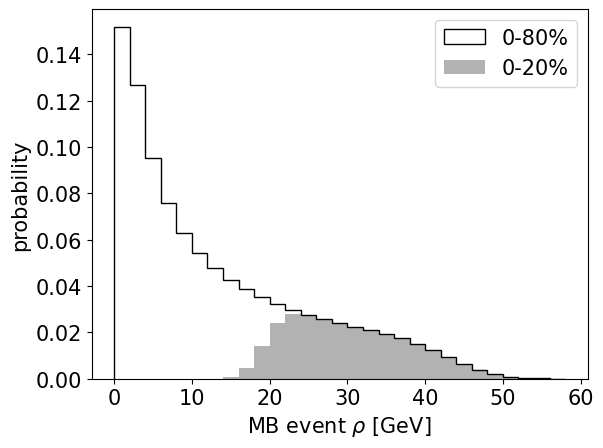

In [17]:
plt.hist(df_mb['rho'], bins=np.arange(0,60,2), histtype='step', weights=np.ones(df_mb.shape[0])*(1/df_mb.shape[0]), label='0-80%', color='k')
plt.hist(df_mb[df_mb.centrality>=12]['rho'], bins=np.arange(0,60,2), alpha=0.3, weights=np.ones(df_mb[df_mb.centrality>=12].shape[0])*(1/df_mb.shape[0]), label='0-20%', color='k')
plt.xlabel(r'MB event $\rho$ [GeV]')
plt.ylabel('probability')
plt.legend()

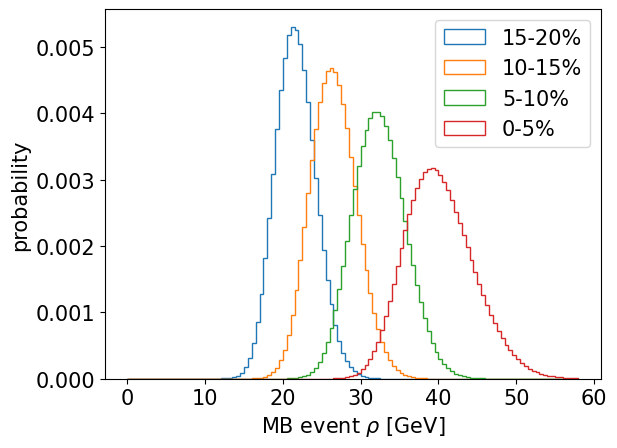

In [16]:
plt.hist(df_mb[df_mb.centrality==12]['rho'], bins=np.arange(0,58.5,0.5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==12].shape[0])*(1/df_mb.shape[0]), label='15-20%')
plt.hist(df_mb[df_mb.centrality==13]['rho'], bins=np.arange(0,58.5,0.5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==13].shape[0])*(1/df_mb.shape[0]), label='10-15%')
plt.hist(df_mb[df_mb.centrality==14]['rho'], bins=np.arange(0,58.5,0.5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==14].shape[0])*(1/df_mb.shape[0]), label='5-10%')
plt.hist(df_mb[df_mb.centrality==15]['rho'], bins=np.arange(0,58.5,0.5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==15].shape[0])*(1/df_mb.shape[0]), label='0-5%')
plt.xlabel(r'MB event $\rho$ [GeV]')
plt.ylabel('probability')
plt.legend()

In [18]:
print(np.average(df_mb[df_mb.centrality==12]['rho']), np.std(df_mb[df_mb.centrality==12]['rho']))

21.644047 2.5985515


In [19]:
print(np.average(df_mb[df_mb.centrality==13]['rho']), np.std(df_mb[df_mb.centrality==13]['rho']))

26.501217 2.9617167


In [20]:
print(np.average(df_mb[df_mb.centrality==14]['rho']), np.std(df_mb[df_mb.centrality==14]['rho']))

32.37793 3.3686306


In [21]:
print(np.average(df_mb[df_mb.centrality==15]['rho']), np.std(df_mb[df_mb.centrality==15]['rho']))

40.14763 4.408927


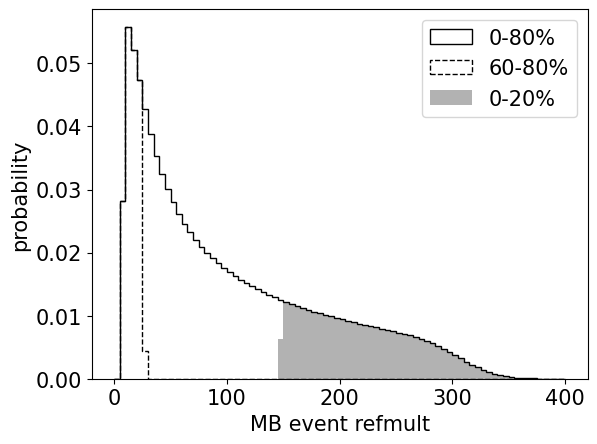

In [31]:
plt.hist(df_mb['refmult'], bins=np.arange(0,405,5), histtype='step', weights=np.ones(df_mb.shape[0])*(1/df_mb.shape[0]), label='0-80%', color='k')
plt.hist(df_mb[df_mb.centrality<=3]['refmult'], bins=np.arange(0,405,5), histtype='step', linestyle='dashed', weights=np.ones(df_mb[df_mb.centrality<=3].shape[0])*(1/df_mb.shape[0]), label='60-80%', color='k')
plt.hist(df_mb[df_mb.centrality>=12]['refmult'], bins=np.arange(0,405,5), alpha=0.3, weights=np.ones(df_mb[df_mb.centrality>=12].shape[0])*(1/df_mb.shape[0]), label='0-20%', color='k')
plt.xlabel('MB event refmult')
plt.ylabel('probability')
plt.legend()

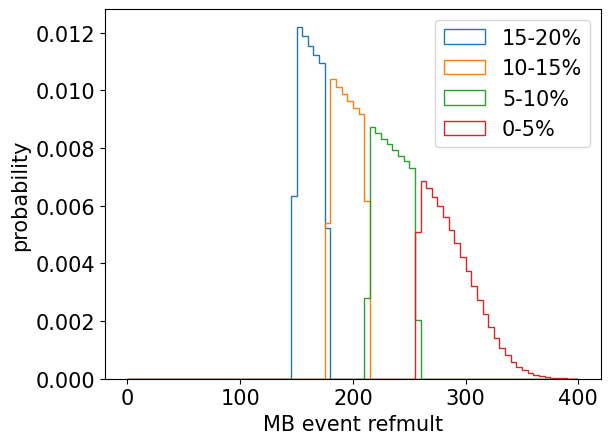

In [32]:
plt.hist(df_mb[df_mb.centrality==12]['refmult'], bins=np.arange(0,405,5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==12].shape[0])*(1/df_mb.shape[0]), label='15-20%')
plt.hist(df_mb[df_mb.centrality==13]['refmult'], bins=np.arange(0,405,5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==13].shape[0])*(1/df_mb.shape[0]), label='10-15%')
plt.hist(df_mb[df_mb.centrality==14]['refmult'], bins=np.arange(0,405,5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==14].shape[0])*(1/df_mb.shape[0]), label='5-10%')
plt.hist(df_mb[df_mb.centrality==15]['refmult'], bins=np.arange(0,405,5), histtype='step', weights=np.ones(df_mb[df_mb.centrality==15].shape[0])*(1/df_mb.shape[0]), label='0-5%')
plt.xlabel('MB event refmult')
plt.ylabel('probability')
plt.legend()

In [26]:
observables = ['runnumber','eventnumber','centrality','rho']

In [27]:
filename = '/gpfs/gibbs/project/havener/ys668/other_output/rc/isobar/ht_evt_49run57.root'
treename = 'event_tree'

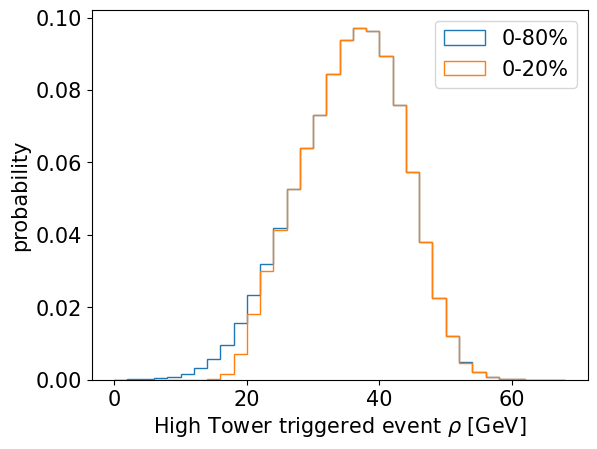

In [56]:
plt.hist(df['rho'], bins=np.arange(0,70,2), histtype='step', weights=np.ones(df.shape[0])*(1/df.shape[0]), label='0-80%')
plt.hist(df[df.centrality>=12]['rho'], bins=np.arange(0,70,2), histtype='step', weights=np.ones(df[df.centrality>=12].shape[0])*(1/df.shape[0]), label='0-20%')
plt.xlabel(r'High Tower triggered event $\rho$ [GeV]')
plt.ylabel('probability')
plt.legend()

In [57]:
print(np.average(df[df.centrality>=12]['rho']), np.std(df[df.centrality>=12]['rho']))

36.00869 7.353644
